# Reporte descriptivo de contratación en SECOP 2

Monitoría de investigación - Beca Avanza, Universidad de los Andes. **Entregable 3.**

En este cuaderno describimos cómo contratan tres entidades públicas: cuántos contratos firman, de qué tipo, por cuánto dinero, con cuántos proveedores y cada cuánto se prorrogan.

Los datos salen del mismo pipeline del repositorio: se descargan los contratos y los procesos del portal de datos abiertos y se unen en una sola tabla, con una fila por contrato.

Empecemos importando las librerías y los módulos del proyecto

In [1]:
import sys
sys.path.append('..')
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src import indicadores as ind
from src.flujo_vigia import construir_base_contratos

## 1. Qué vamos a analizar

Aquí se eligen las entidades y el periodo. Para analizar otras entidades u otras fechas, basta con cambiar esta celda y volver a ejecutar todo el cuaderno.

In [2]:
# Nombre de la entidad como aparece en SECOP 2 y la sigla que usaremos en las tablas
ENTIDADES = {
    'AGENCIA NACIONAL DE TIERRAS - ANT': 'ANT',
    'UNP': 'UNP',
    'AGENCIA PARA LA REINCORPORACIÓN Y LA NORMALIZACIÓN': 'ARN',
}
DESDE = '2022-01-01'   # fecha de firma del contrato, desde
HASTA = '2026-11-23'   # fecha de firma del contrato, hasta

## 2. Carguemos los datos

La primera vez el cuaderno descarga los datos del portal (tarda unos minutos) y los guarda en `data/processed/`. Las siguientes veces los lee de ese archivo.

Solo guardamos las columnas que vamos a usar. La tabla original tiene más de 150 y algunas traen datos personales que no necesitamos.

In [3]:
COLUMNAS = [
    'nombre_entidad', 'id_contrato', 'proceso_de_compra', 'estado_contrato',
    'tipo_de_contrato', 'modalidad_de_contratacion', 'justificacion_modalidad_de',
    'fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato',
    'dias_firma_a_inicio', 'dias_inicio_a_fin', 'proveedor_adjudicado', 'documento_proveedor',
    'tipodocproveedor', 'es_pyme', 'valor_del_contrato', 'valor_pagado', 'dias_adicionados',
    'destino_gasto', 'origen_de_los_recursos', 'precio_base', 'respuestas_al_procedimiento',
    'fecha_de_publicacion_del',
]
FECHAS = ['fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato',
          'fecha_de_publicacion_del']

archivo = Path('../data/processed') / f"reporte_{'_'.join(ENTIDADES.values())}_{DESDE}_{HASTA}.csv.gz"

if archivo.exists():
    df = pd.read_csv(archivo, parse_dates=FECHAS, low_memory=False)
else:
    config = {'filtros': {'nombre_entidad': list(ENTIDADES),
                          'fecha_de_firma': {'desde': DESDE, 'hasta': HASTA}}}
    base = construir_base_contratos(config, limite=None)
    df = base[[c for c in COLUMNAS if c in base.columns]]
    df.to_csv(archivo, index=False)

for col in ['valor_del_contrato', 'valor_pagado', 'dias_adicionados', 'precio_base',
            'respuestas_al_procedimiento']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['entidad'] = df['nombre_entidad'].map(ENTIDADES)
df['año'] = df['fecha_de_firma'].dt.year

Exploremos el tamaño del df

In [4]:
df.shape

(60933, 26)

Veamos cuántos contratos tiene cada entidad

In [5]:
df['entidad'].value_counts()

entidad
ANT    40441
UNP    12578
ARN     7914
Name: count, dtype: int64

## 3. Revisemos la calidad de los datos

Antes de sacar cifras conviene saber si hay registros raros: fechas que faltan, valores en cero o valores exageradamente altos. Esta revisión no cambia nada en los datos, solo nos avisa.

In [6]:
for sigla, g in df.groupby('entidad'):
    print(sigla, f'({len(g)} contratos)')
    print(ind.calidad_datos(g).to_string(index=False), '\n')

ANT (40441 contratos)
                                         revisión  casos
           Firma posterior al inicio del contrato     13
                   Sin fecha de inicio o de firma    206
                               Valor cero o vacío     19
Valor más de 1.000 veces la mediana ($38.108.268)      6 

ARN (7914 contratos)
                      revisión  casos
Sin fecha de inicio o de firma      2
            Valor cero o vacío     26 

UNP (12578 contratos)
                                         revisión  casos
           Firma posterior al inicio del contrato      2
                   Sin fecha de inicio o de firma     25
                               Valor cero o vacío     18
Valor más de 1.000 veces la mediana ($39.666.667)     59 



Identificamos NAs en los datos (porcentaje de valores vacíos por columna)

In [7]:
(100 * df.isna().mean()).round(1).sort_values(ascending=False).head(10)

fecha_de_inicio_del_contrato    0.4
dias_firma_a_inicio             0.4
dias_inicio_a_fin               0.4
respuestas_al_procedimiento     0.2
precio_base                     0.2
fecha_de_publicacion_del        0.2
id_contrato                     0.0
proceso_de_compra               0.0
tipo_de_contrato                0.0
nombre_entidad                  0.0
dtype: float64

Son pocos casos. Los valores "más de 1.000 veces la mediana" los revisamos uno por uno: son contratos grandes de verdad (los vemos en la sección 6), no errores de digitación.

## 4. Una mirada general

Para cada entidad: número de contratos, valor total, valor del contrato típico (la mediana), y qué porcentaje se hizo por contratación directa, se prorrogó o se firmó después de haber empezado.

In [8]:
resumen = pd.DataFrame({sigla: ind.resumen(g) for sigla, g in df.groupby('entidad')}).T
resumen['valor_total'] = resumen['valor_total'] / 1e9
resumen['valor_mediano'] = resumen['valor_mediano'] / 1e6
resumen.columns = ['contratos', 'valor total (miles de millones)', 'valor mediano (millones)',
                   '% contratación directa', '% con prórroga', '% firmado después de iniciar']
resumen['contratos'] = resumen['contratos'].astype(int)
resumen.round(1)

,contratos,valor total (miles de millones),valor mediano (millones),% contratación directa,% con prórroga,% firmado después de iniciar
ANT,40441,4360.4,38.1,97.6,9.8,0.0
ARN,7914,910.8,48.5,97.7,3.5,0.0
UNP,12578,10908.1,39.7,97.1,22.5,0.0


Las tres entidades contratan casi todo de forma directa (sin convocatoria abierta) y su contrato típico vale entre 38 y 49 millones de pesos. La gran diferencia está en el valor total y en las prórrogas: la UNP mueve mucho más dinero y prorroga más.

## 5. ¿Cómo cambia la contratación de un año a otro?

Contratos firmados y valor por año. Ojo: el último año todavía no termina.

In [9]:
por_anio = df.groupby(['año', 'entidad']).agg(contratos=('id_contrato', 'size'),
                                             valor=('valor_del_contrato', 'sum'))
por_anio['valor'] = por_anio['valor'] / 1e9
por_anio.unstack('entidad').round(1)

contratos               valor               
entidad       ANT   ARN   UNP     ANT    ARN     UNP
año                                                 
2022         1466  1310  1503   117.3  151.6  1367.7
2023         5542  2163  2379   505.8  209.2  6540.1
2024        11870  1511  2443  2424.6  143.2   961.4
2025        11746  1590  3266   708.1  284.7  1441.4
2026         9817  1340  2987   604.6  122.0   597.5

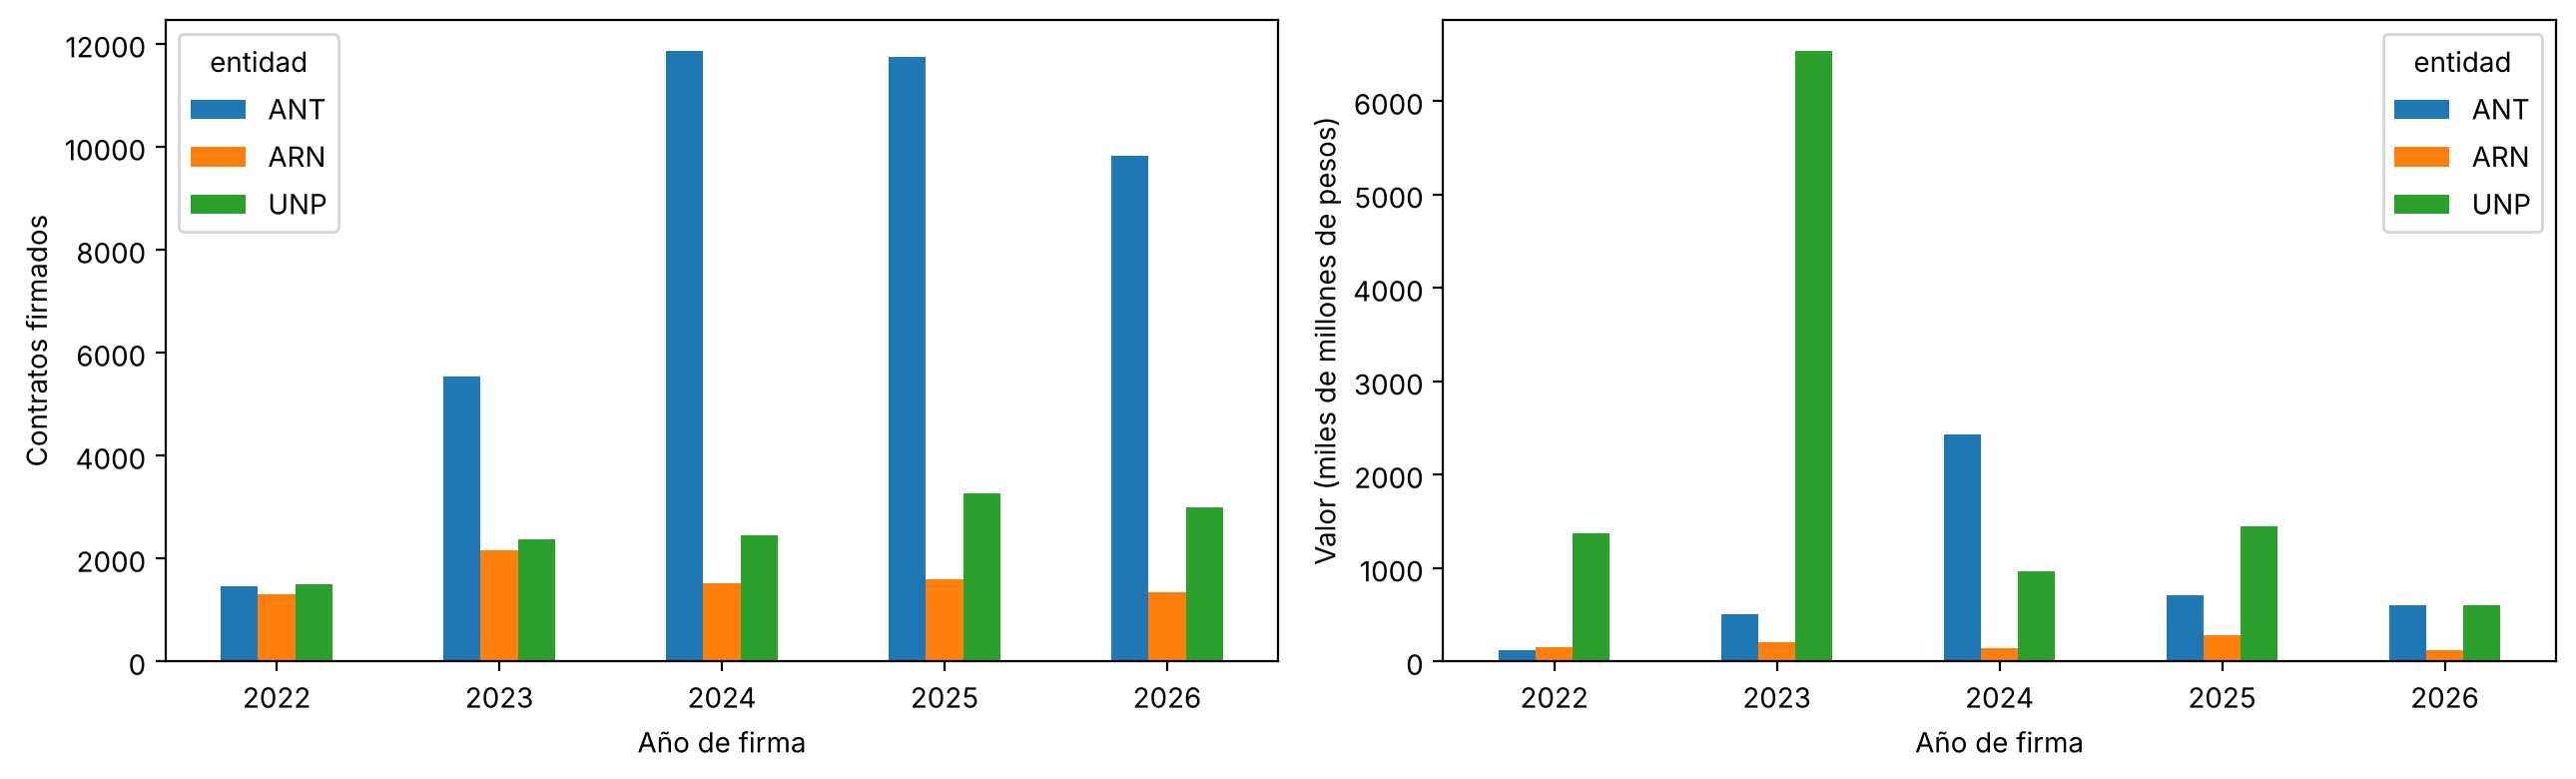

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
por_anio['contratos'].unstack('entidad').plot.bar(ax=ax[0])
ax[0].set_ylabel('Contratos firmados')
por_anio['valor'].unstack('entidad').plot.bar(ax=ax[1])
ax[1].set_ylabel('Valor (miles de millones de pesos)')
for a in ax:
    a.set_xlabel('Año de firma')
    a.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

La ANT es la que más contratos firma desde 2024. En valor, en cambio, se ven picos de un solo año: la UNP en 2023 y la ANT en 2024. Esos picos los explican unos pocos contratos muy grandes, que veremos más adelante.

## 6. ¿Cómo contratan?

### Modalidad de contratación

Porcentaje de los contratos y del valor de cada entidad en cada modalidad.

In [11]:
modalidades = []
for sigla, g in df.groupby('entidad'):
    t = ind.por_modalidad(g)
    t['% contratos'] = 100 * t['contratos'] / t['contratos'].sum()
    t['% valor'] = 100 * t['valor'] / t['valor'].sum()
    t['entidad'] = sigla
    modalidades.append(t)
modalidades = pd.concat(modalidades).reset_index()
modalidades.set_index(['modalidad', 'entidad'])[['% contratos', '% valor']].unstack('entidad').fillna(0).round(1)

% contratos              \
entidad                                                    ANT   ARN   UNP   
modalidad                                                                    
Concurso de méritos abierto                                0.0   0.2   0.0   
Contratación Directa (con ofertas)                         0.2   0.0   0.1   
Contratación directa                                      97.4  97.7  97.0   
Contratación régimen especial                              2.2   0.3   0.0   
Contratación régimen especial (con ofertas)                0.0   0.0   0.0   
Licitación pública                                         0.0   0.2   0.1   
Licitación pública Obra Publica                            0.0   0.0   0.0   
Mínima cuantía                                             0.1   0.6   1.0   
Seleccion Abreviada Menor Cuantia Sin Manifesta...         0.0   0.0   0.0   
Selección Abreviada de Menor Cuantía                       0.0   0.6   1.4   
Selección abreviada subasta inversa                        0.1   0.5   0.3   

                                                   % valor              
entidad                                                ANT   ARN   UNP  
modalidad                                                               
Concurso de méritos abierto                            0.0   1.1   0.0  
Contratación Directa (con ofertas)                    48.2   0.1   0.2  
Contratación directa                                  43.1  60.4  13.7  
Contratación régimen especial                          5.5  12.4   0.3  
Contratación régimen especial (con ofertas)            0.2   0.9   0.0  
Licitación pública                                     0.0  12.9   1.2  
Licitación pública Obra Publica                        0.1   0.0   0.0  
Mínima cuantía                                         0.1   0.1   0.1  
Seleccion Abreviada Menor Cuantia Sin Manifesta...     0.0   0.0   0.0  
Selección Abreviada de Menor Cuantía                   0.1   8.4  82.8  
Selección abreviada subasta inversa                    2.7   3.6   1.8

Aquí aparece algo importante: **contar contratos y sumar dinero cuentan historias distintas.**

- En la UNP, la selección abreviada de menor cuantía es solo el 1,4 % de los contratos, pero el 82,8 % del dinero.
- En la ANT, la contratación directa "con ofertas" es el 0,2 % de los contratos y casi la mitad del dinero (48,2 %).

Veamos cuáles son esos contratos tan grandes:

In [12]:
grandes = df.sort_values('valor_del_contrato', ascending=False).groupby('entidad').head(3).copy()
grandes['valor (millones)'] = (grandes['valor_del_contrato'] / 1e6).round()
grandes[['entidad', 'valor (millones)', 'tipo_de_contrato', 'modalidad_de_contratacion', 'año']]

,entidad,valor (millones),tipo_de_contrato,modalidad_de_contratacion,año
56360,ANT,500000.0,Otro,Contratación Directa (con ofertas),2024
19958,ANT,500000.0,Otro,Contratación Directa (con ofertas),2024
37536,UNP,491446.0,Prestación de servicios,Selección Abreviada de Menor Cuantía,2023
53797,ANT,410000.0,Otro,Contratación Directa (con ofertas),2024
49630,UNP,359457.0,Prestación de servicios,Selección Abreviada de Menor Cuantía,2023
51446,UNP,333908.0,Prestación de servicios,Selección Abreviada de Menor Cuantía,2023
34871,ARN,48010.0,Decreto 092 de 2017,Contratación régimen especial,2025
119,ARN,40768.0,Prestación de servicios,Licitación pública,2023
25191,ARN,26611.0,Arrendamiento de inmuebles,Contratación directa,2023


### Tipo de contrato (porcentaje de los contratos de cada entidad)

In [13]:
tipos = df.groupby('entidad')['tipo_de_contrato'].value_counts(normalize=True) * 100
tipos.unstack('entidad').fillna(0).round(1).sort_values('ANT', ascending=False).head(8)

entidad,ANT,ARN,UNP
tipo_de_contrato,,,
Prestación de servicios,97.2,95.5,97.4
Otro,2.2,0.9,0.3
Arrendamiento de inmuebles,0.4,2.1,1.0
Compraventa,0.1,0.5,0.6
Comodato,0.0,0.0,0.0
Consultoría,0.0,0.2,0.0
Comisión,0.0,0.0,0.0
Arrendamiento de muebles,0.0,0.0,0.1


### ¿Por qué se contrata directamente?

Cada contrato directo registra la razón (causal) por la que se hizo así. Estas son las cinco más usadas en cada entidad.

In [14]:
for sigla, g in df.groupby('entidad'):
    print(sigla)
    print(ind.justificacion_directa(g)[['contratos', '% de los directos']].head(5), '\n')

ANT
                                                    contratos  \
causal                                                          
Servicios profesionales y apoyo a la gestión            39132   
Arrendamiento de inmuebles                                178   
Contratos o convenios Interadministrativos (con...         56   
Contratos o convenios Interadministrativos (val...         39   
No existe pluralidad de oferentes en el mercado            27   

                                                    % de los directos  
causal                                                                 
Servicios profesionales y apoyo a la gestión                    99.17  
Arrendamiento de inmuebles                                       0.45  
Contratos o convenios Interadministrativos (con...               0.14  
Contratos o convenios Interadministrativos (val...               0.10  
No existe pluralidad de oferentes en el mercado                  0.07   

ARN
                              

Casi todos los contratos directos son de servicios profesionales y apoyo a la gestión, es decir, personas contratadas para trabajar en la entidad.

## 7. Separemos los contratos de servicios profesionales

Como son tantos y tan parecidos, los contratos de servicios profesionales tapan al resto cuando se cuentan contratos. Por eso los comparamos por separado.

In [15]:
grupos = pd.concat({sigla: ind.comparar_prestacion(g) for sigla, g in df.groupby('entidad')},
                   names=['entidad', 'grupo'])
grupos['valor'] = grupos['valor'] / 1e9
grupos['valor_mediano'] = grupos['valor_mediano'] / 1e6
grupos.columns = ['contratos', '% de contratos', 'valor (miles de millones)', '% del valor',
                  'valor mediano (millones)']
grupos.round(1)

contratos  % de contratos  \
entidad grupo                                                              
ANT     Prestación de servicios profesionales      39132            96.8   
        Resto de la contratación                    1309             3.2   
ARN     Prestación de servicios profesionales       7458            94.2   
        Resto de la contratación                     456             5.8   
UNP     Prestación de servicios profesionales      11925            94.8   
        Resto de la contratación                     653             5.2   

                                               valor (miles de millones)  \
entidad grupo                                                              
ANT     Prestación de servicios profesionales                     1708.6   
        Resto de la contratación                                  2651.8   
ARN     Prestación de servicios profesionales                      367.9   
        Resto de la contratación                                   542.8   
UNP     Prestación de servicios profesionales                      532.7   
        Resto de la contratación                                 10375.4   

                                               % del valor  \
entidad grupo                                                
ANT     Prestación de servicios profesionales         39.2   
        Resto de la contratación                      60.8   
ARN     Prestación de servicios profesionales         40.4   
        Resto de la contratación                      59.6   
UNP     Prestación de servicios profesionales          4.9   
        Resto de la contratación                      95.1   

                                               valor mediano (millones)  
entidad grupo                                                            
ANT     Prestación de servicios profesionales                      38.1  
        Resto de la contratación                                   57.0  
ARN     Prestación de servicios profesionales                      47.5  
        Resto de la contratación                                  116.1  
UNP     Prestación de servicios profesionales                      38.4  
        Resto de la contratación                                  450.0

Los servicios profesionales son entre el 94 % y el 97 % de los contratos, pero solo el 39 % del dinero en la ANT, el 40 % en la ARN y el 5 % en la UNP. El resto del dinero está en pocos contratos de otro tipo.

## 8. ¿Por cuánto son los contratos?

Estadísticas descriptivas del valor (en millones de pesos)

In [16]:
valores = df.groupby('entidad')['valor_del_contrato'].describe(percentiles=[.25, .5, .75, .9, .99])
valores.iloc[:, 1:] = valores.iloc[:, 1:] / 1e6
valores.round(1)

,count,mean,std,min,25%,50%,75%,90%,99%,max
entidad,,,,,,,,,,
ANT,40441.0,107.8,4370.9,0.0,26.8,38.1,54.6,77.3,165.4,500000.0
ARN,7914.0,115.1,975.1,0.0,25.7,48.5,65.5,94.9,1345.2,48010.3
UNP,12578.0,867.2,11660.1,0.0,23.4,39.7,60.0,83.6,11723.7,491445.6


El promedio (`mean`) es mucho más alto que la mediana (`50%`) porque unos pocos contratos enormes lo jalan hacia arriba. Por eso usamos la mediana para hablar del contrato típico.

Contratos por rango de valor

In [17]:
pd.DataFrame({sigla: ind.distribucion_valores(g)['contratos'] for sigla, g in df.groupby('entidad')}).fillna(0).astype(int)

,ANT,ARN,UNP
valor_del_contrato,,,
menos de 1M,2,2,3
1M – 10M,932,305,690
10M – 100M,37764,6953,11111
100M – 1.000M,1579,542,463
1.000M – 10.000M,118,77,155
10.000M – 100.000M,23,9,111
más de 100.000M,4,0,27


Diagrama de caja del valor. Usamos el logaritmo del valor porque, sin él, los contratos más grandes aplastan a todos los demás y no se ve nada. Un punto más en el eje equivale a multiplicar el valor por 10.

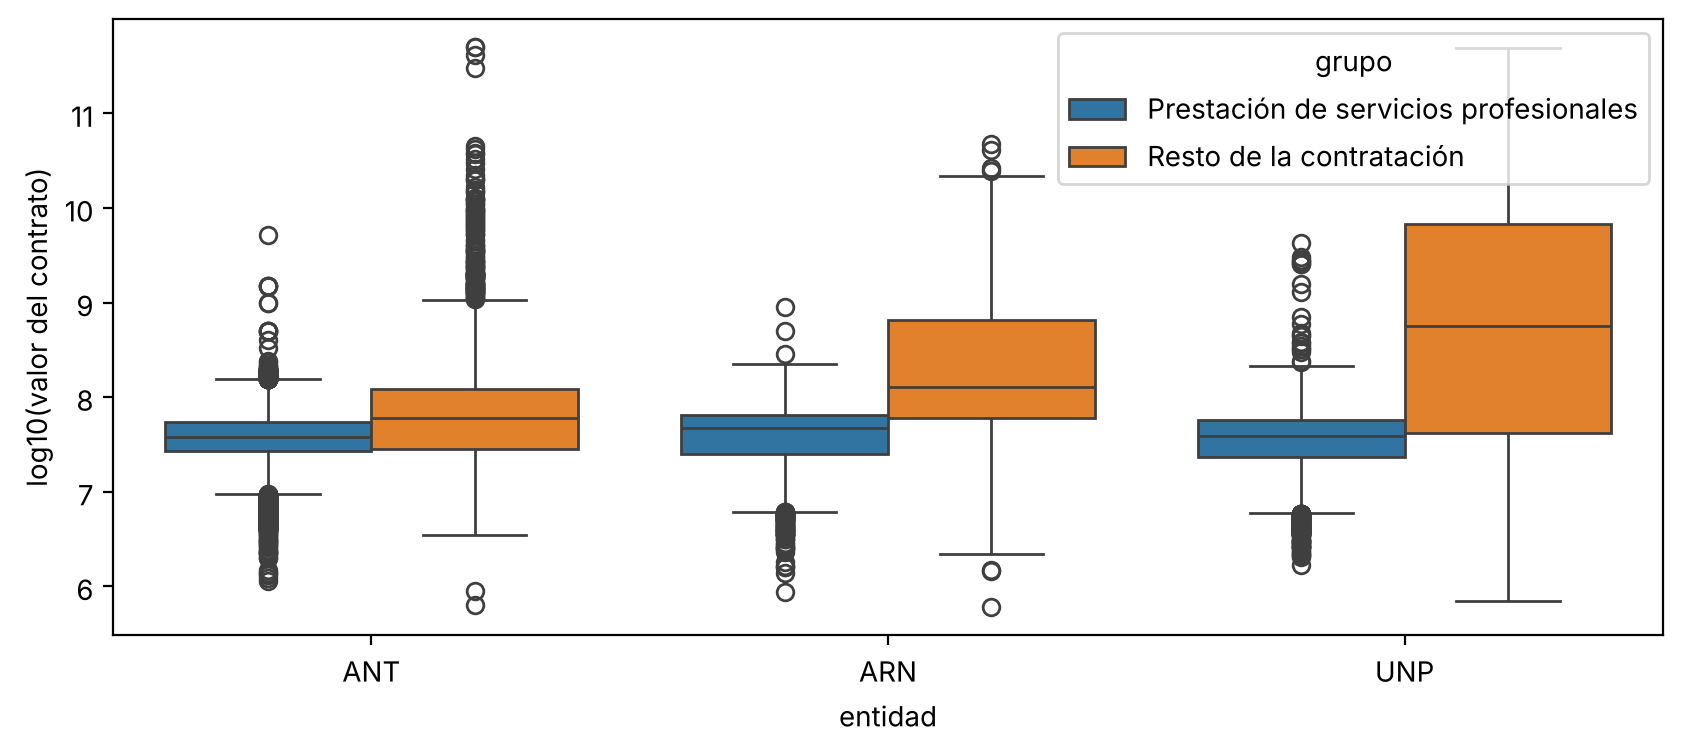

In [18]:
df['grupo'] = ind.grupo_prestacion(df)
df['log10_valor'] = np.log10(df['valor_del_contrato'].where(df['valor_del_contrato'] > 0))
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='entidad', y='log10_valor', hue='grupo')
plt.ylabel('log10(valor del contrato)')
plt.show()

Los contratos de servicios profesionales tienen valores muy parecidos entre sí (cajas angostas). Los demás contratos varían muchísimo, sobre todo en la UNP.

## 9. Tiempos

### De la firma al inicio

¿Cuántos días pasan entre que se firma el contrato y que empieza? Un contrato firmado después de haber empezado sería una alerta.

In [19]:
tramos = {sigla: ind.distribucion_firma_a_inicio(g).sum(axis=1) for sigla, g in df.groupby('entidad')}
pd.DataFrame(tramos)

,ANT,ARN,UNP
Firmado tras iniciar,13,0,2
Mismo día,9821,1704,4526
1 a 7 días,28089,5701,7170
8 a 30 días,2169,498,844
Más de 30 días,143,9,11


La gran mayoría empieza el mismo día o en la semana siguiente. Solo 15 contratos se firmaron después de haber empezado.

### Duración del contrato (días de inicio a fin)

In [20]:
df.groupby('entidad')['dias_inicio_a_fin'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
entidad,,,,,,,,
ANT,40235.0,174.6,97.3,0.0,123.0,160.0,214.5,4382.0
ARN,7912.0,266.1,117.3,0.0,177.0,317.0,342.0,2191.0
UNP,12553.0,224.4,120.5,0.0,123.0,226.0,340.0,2191.0


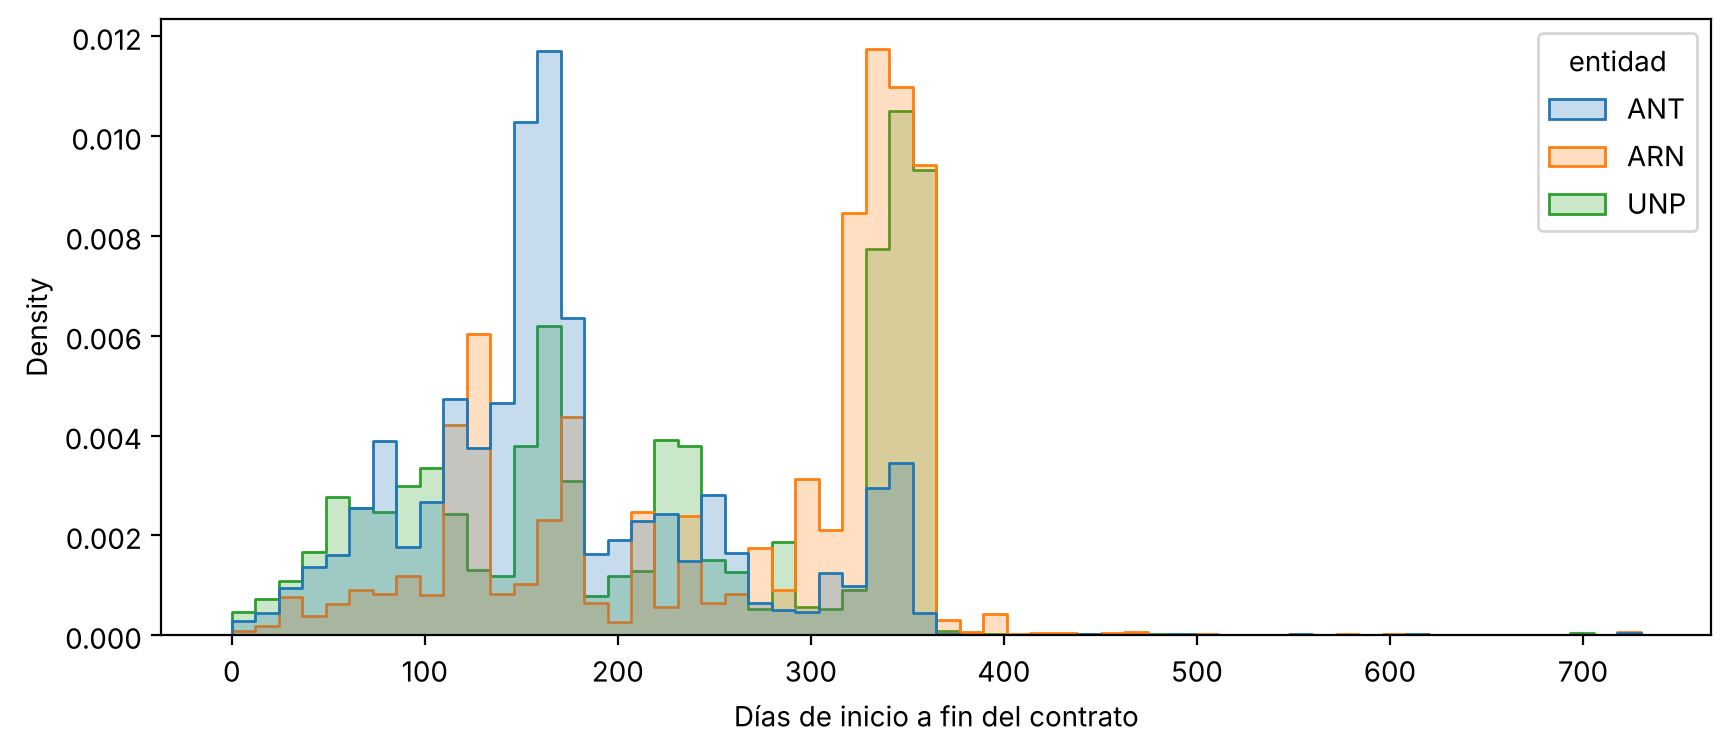

In [21]:
plt.figure(figsize=(10, 4))
sns.histplot(data=df[df['dias_inicio_a_fin'].between(0, 730)], x='dias_inicio_a_fin',
             hue='entidad', stat='density', common_norm=False, bins=60, element='step')
plt.xlabel('Días de inicio a fin del contrato')
plt.show()

Los contratos de la ANT suelen ser más cortos (mediana de 160 días) que los de la UNP (226) y la ARN (317).

### De la publicación del proceso a la firma

In [22]:
df['dias_publicacion_a_firma'] = (df['fecha_de_firma'] - df['fecha_de_publicacion_del']).dt.days
df.groupby('entidad')['dias_publicacion_a_firma'].describe(percentiles=[.5, .9]).round(1)

,count,mean,std,min,50%,90%,max
entidad,,,,,,,
ANT,40347.0,2.4,5.3,0.0,1.0,6.0,194.0
ARN,7897.0,2.9,7.9,0.0,0.0,8.0,123.0
UNP,12544.0,1.7,6.7,0.0,0.0,3.0,160.0


La mitad de los contratos se firma el mismo día o al día siguiente de publicar el proceso. Tiene sentido: en la contratación directa no hay que esperar ofertas.

## 10. ¿Cuántas ofertas reciben?

Número de ofertas según la modalidad. En la contratación directa no hay convocatoria, así que lo normal es que no haya ofertas; en las modalidades con convocatoria sí se esperan.

In [23]:
for sigla, g in df.groupby('entidad'):
    print(sigla)
    print(ind.ofertas_por_modalidad(g), '\n')

ANT
respuestas_al_procedimiento                  Sin ofertas  Una oferta  \
modalidad_de_contratacion                                              
Contratación directa                               39299           0   
Contratación régimen especial                        885           0   
Contratación Directa (con ofertas)                     0          66   
Mínima cuantía                                         1           9   
Selección abreviada subasta inversa                    8           2   
Selección Abreviada de Menor Cuantía                   7           1   
Contratación régimen especial (con ofertas)            0           4   
Concurso de méritos abierto                            0           2   
Licitación pública                                     0           0   
Licitación pública Obra Publica                        1           0   

respuestas_al_procedimiento                  Dos o más  Total  
modalidad_de_contratacion                                      
Con

## 11. Proveedores

¿El dinero se reparte entre muchos proveedores o se concentra en pocos? Mostramos qué parte de los contratos y del dinero se llevan los 10 proveedores más grandes de cada entidad. Solo mostramos porcentajes, porque muchos proveedores son personas naturales.

In [24]:
conc = {}
for sigla, g in df.groupby('entidad'):
    c = ind.concentracion_proveedores(g, n=10)
    conc[sigla] = {'proveedores distintos': c['proveedores'],
                   'contratos por proveedor': len(g) / c['proveedores'],
                   '% de contratos de los 10 mayores': c['pct_contratos'],
                   '% del valor de los 10 mayores': c['pct_valor']}
conc = pd.DataFrame(conc).T
conc['proveedores distintos'] = conc['proveedores distintos'].astype(int)
conc.round(1)

,proveedores distintos,contratos por proveedor,% de contratos de los 10 mayores,% del valor de los 10 mayores
ANT,14841,2.7,0.1,49.5
ARN,2987,2.6,0.5,33.5
UNP,4083,3.1,0.6,48.1


Cada proveedor tiene en promedio 2 o 3 contratos. Los 10 más grandes tienen menos del 1 % de los contratos, pero se llevan entre un tercio y la mitad del dinero.

## 12. Prórrogas

Porcentaje de contratos que se prorrogaron (que tienen días adicionados), por año de firma.

Solo contamos contratos que **ya terminaron**: uno que sigue en ejecución todavía puede prorrogarse. Aun así, el último año no se puede comparar con los demás, porque de los contratos firmados ese año solo han terminado los más cortos. Por eso mostramos también cuántos contratos hay detrás de cada porcentaje.

In [25]:
terminados = df[df['fecha_de_fin_del_contrato'] < pd.Timestamp(HASTA)].copy()
terminados['con_prorroga'] = terminados['dias_adicionados'] > 0
tasa = 100 * terminados.groupby(['año', 'entidad'])['con_prorroga'].mean().unstack('entidad')
n = terminados.groupby(['año', 'entidad']).size().unstack('entidad')
pd.concat({'% con prórroga': tasa.round(1), 'contratos terminados': n}, axis=1)

% con prórroga            contratos terminados            
entidad            ANT  ARN   UNP                  ANT   ARN   UNP
año                                                               
2022               2.0  0.5   4.3                 1465  1308  1502
2023               0.9  0.0  18.6                 5538  2159  2365
2024              12.1  3.2  15.4                11861  1499  2435
2025               9.0  2.2  41.9                11656  1540  3255
2026              19.5  1.9  76.2                 5746    52   618

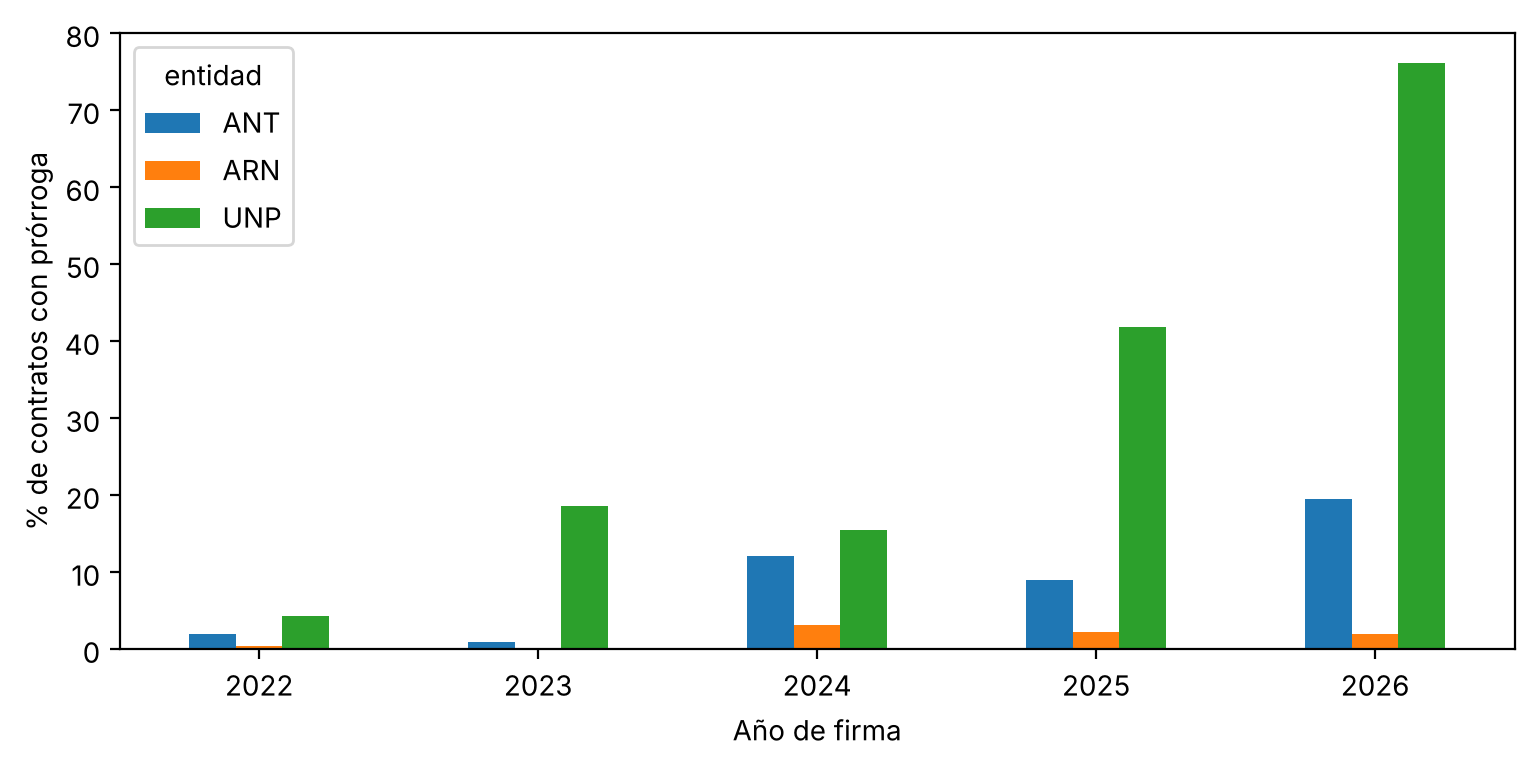

In [26]:
tasa.plot.bar(figsize=(9, 4))
plt.ylabel('% de contratos con prórroga')
plt.xlabel('Año de firma')
plt.xticks(rotation=0)
plt.show()

¿De cuántos días son las prórrogas?

In [27]:
terminados[terminados['con_prorroga']].groupby('entidad')['dias_adicionados'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
entidad,,,,,,,,
ANT,3682.0,85.1,32.0,1.0,61.0,92.0,92.0,547.0
ARN,89.0,55.7,68.0,6.0,16.0,16.0,89.0,407.0
UNP,2716.0,84.9,34.5,1.0,61.0,86.0,115.0,366.0


En la UNP las prórrogas son mucho más frecuentes ahora que al principio: pasan de 4,3 % de los contratos firmados en 2022 a 41,9 % en 2025. En la ANT y la UNP una prórroga típica es de unos 3 meses (mediana de 92 y 86 días); en la ARN, de 16 días.

## 13. ¿En qué meses se firma?

Contratos firmados por mes del año, sumando todos los años

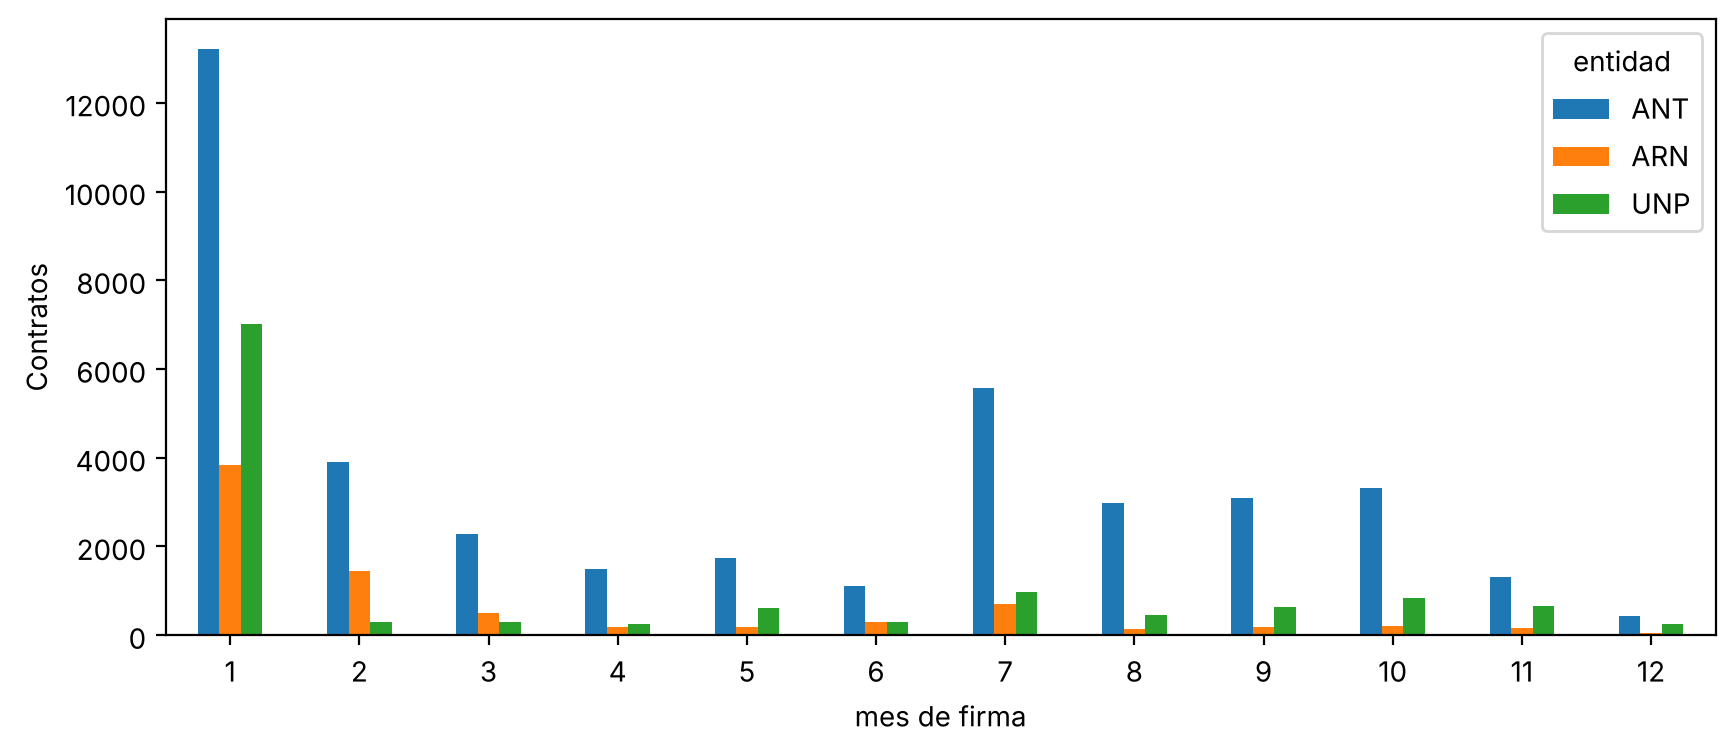

In [28]:
mes = df.groupby([df['fecha_de_firma'].dt.month, 'entidad']).size().unstack('entidad')
mes.index.name = 'mes de firma'
mes.plot.bar(figsize=(10, 4))
plt.ylabel('Contratos')
plt.xticks(rotation=0)
plt.show()

Enero concentra la mayor parte de las firmas: es cuando las entidades vuelven a contratar a su personal para el año. Veamos ahora mes a mes, año por año:

In [29]:
por_mes = df.groupby(['año', df['fecha_de_firma'].dt.month]).size().unstack(0).fillna(0).astype(int)
por_mes.index.name = 'mes de firma'
por_mes

año,2022,2023,2024,2025,2026
mes de firma,,,,,
1,3218,2640,4863,3578,9783
2,28,1264,1415,2891,32
3,16,941,742,1310,60
4,14,652,264,938,68
5,13,943,577,838,157
6,26,537,589,470,61
7,142,1098,2346,1029,2645
8,120,462,1674,797,536
9,134,599,1008,2124,67


En 2022 y en 2026, de febrero a junio casi no se firmaron contratos, algo que no pasa en los demás años. Vale la pena preguntar a qué se debe.

## 14. Conclusiones

Analizamos 60.933 contratos firmados entre enero de 2022 y noviembre de 2026: 40.441 de la ANT, 12.578 de la UNP y 7.914 de la ARN.

1. **Casi todo se contrata de forma directa.** Más del 97 % de los contratos de las tres entidades es contratación directa, y casi siempre se trata de servicios profesionales: personas contratadas para trabajar en la entidad. El contrato típico vale entre 38 y 49 millones de pesos.

2. **Pero el dinero está en pocos contratos.** Los servicios profesionales son entre el 94 % y el 97 % de los contratos, pero solo el 39 % del dinero en la ANT, el 40 % en la ARN y el 5 % en la UNP. En la UNP, unos pocos contratos firmados en diciembre de 2023, de hasta 491.000 millones de pesos cada uno, explican el pico de ese año. En la ANT pasa algo parecido en 2024.

3. **Contar contratos no es suficiente.** Si solo se cuentan contratos, todo se ve igual en las tres entidades. Hay que mirar también el dinero y separar los servicios profesionales del resto.

4. **Los tiempos son los de la contratación directa.** Los contratos se firman el mismo día o al día siguiente de publicar el proceso y casi nunca hay ofertas. Esto es lo normal en esa modalidad, no una alerta. Solo 15 contratos se firmaron después de haber empezado.

5. **Pocos proveedores se llevan buena parte del dinero.** Los 10 proveedores más grandes de cada entidad tienen menos del 1 % de los contratos, pero entre el 34 % (ARN) y el 50 % (ANT) del dinero.

6. **La UNP prorroga cada vez más.** El 22,5 % de sus contratos tiene prórroga, frente al 9,8 % de la ANT y el 3,5 % de la ARN. Entre sus contratos ya terminados, pasó de 4,3 % (firmados en 2022) a 41,9 % (firmados en 2025).

7. **La contratación sigue un ciclo.** Enero es el mes con más firmas. En 2022 y 2026 casi no hubo firmas de febrero a junio.

**Sobre los datos:** 233 contratos no tienen fecha de inicio o de firma y 63 tienen valor cero o vacío. Son pocos y no cambian las conclusiones.